# Filbin et al. 2018 — H3-K27M Glioma
## 05 · Per-gene module correlation & Gate 3 verdict

The decisive **Gate 3** test (Puram-05 protocol): on the **Mixed hub**, correlate each Gast-or-pSom
gene to the Gast and pSom module scores, then take the **mutual correlation** of the two loading
vectors. A **negative** hub *r* is competitive cross-repression (the bifurcation signature). Anchor:
Puram Mixed hub *r* = -0.49. A permutation null (shuffled pSom) confirms the value is real, not a
selection/collider artifact.

In [ ]:
import os, sys, re, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # e.g. Filbin2018_Brain-9  (attempt suffix)
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition (Brain)
dset = re.sub(r'-\d+$', '', name)                       # strip -N attempt suffix -> input folder key
pth  = os.path.join(*([os.pardir]*4))                 # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dset)                       # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)   # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
FEAT = os.path.join(pth_data, 'features', 'biomart')
print('dataset:', name, '| category:', cat)

dataset: Filbin2018_Brain-9 | category: Brain


In [ ]:
c_dict = {'Gast': plt.cm.tab20c(12), 'pSom': plt.cm.tab20c(8), 'Both': 'darkgrey'}

### Load signatures & select module genes (Gast OR pSom) on the Mixed hub

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
get_feat = lambda p: pd.read_csv(p).hsapiens.dropna()
gast = get_feat(os.path.join(FEAT, 'GSE162534.csv'))
psom = get_feat(os.path.join(FEAT, 'GSE229103.csv'))
g = pd.merge(gast, psom, 'outer').hsapiens.drop_duplicates()
g = g[g.isin(adata.var_names)]
adata_plt = adata[adata.obs.celltype == 'Mixed', g].copy()
print('Mixed hub cells:', adata_plt.n_obs, '| Gast|pSom genes:', g.size)

Mixed hub cells: 761 | Gast|pSom genes: 146


### Per-gene correlation to each module -> rank

In [ ]:
X = pd.DataFrame(adata_plt.X.toarray(), index=adata_plt.obs_names, columns=g)
X = X.loc[:, X.nunique(axis=0) > 1]
R = pd.DataFrame(index=X.columns)
R['Gast'] = pearsonr(X, adata_plt.obs.GSE162534.values[:, None], axis=0).statistic
R['pSom'] = pearsonr(X, adata_plt.obs.GSE229103.values[:, None], axis=0).statistic
rank = R.abs().sum(axis=1).rank(ascending=False)
R = R.loc[rank.sort_values().index].copy()
gast_s, psom_s = set(gast), set(psom)
ix = R.index
msk_dict = {'Gast': ix.isin(gast_s) & ~ix.isin(psom_s),
            'pSom': ~ix.isin(gast_s) & ix.isin(psom_s),
            'Both': ix.isin(gast_s) & ix.isin(psom_s)}
for mod, msk in msk_dict.items():
    R.loc[msk, 'Module'] = mod
    print(mod, int(msk.sum()))
R['Module'] = pd.Categorical(R.Module, list(reversed(list(msk_dict.keys()))), ordered=True)

Gast 53
pSom 68
Both 25


### Hub mutual correlation (the Gate 3 statistic) + permutation null

In [ ]:
rval = np.corrcoef(*R.loc[~msk_dict['Both'], ['Gast', 'pSom']].values.T)[0, 1].round(2)
print('hub r =', rval, '(anchor Puram -0.49)')
# permutation null: shuffle per-cell pSom score -> breaks Gast<->pSom cell coupling
rng = np.random.default_rng(SEED); nulls = []
a_obs = R.loc[~msk_dict['Both'], 'Gast'].values
Xv = X.values; mod2 = adata_plt.obs.GSE229103.values[:, None]
cols_nb = X.columns[~(X.columns.isin(gast_s) & X.columns.isin(psom_s))]
Xnb = X[cols_nb].values
for _ in range(300):
    perm = rng.permutation(mod2.ravel())[:, None]
    bp = pearsonr(Xnb, perm, axis=0).statistic
    nulls.append(np.corrcoef(a_obs, bp)[0, 1])
nulls = np.array(nulls)
print('permutation null r = %.3f +/- %.3f  (p = %.3f)' % (nulls.mean(), nulls.std(), (nulls <= rval).mean()))
print('VERDICT: %s' % ('REAL cross-repression -> Gate 3 GO' if rval < nulls.mean() - 2*nulls.std() else 'within null -> NO-GO'))

hub r = -0.34 (anchor Puram -0.49)
permutation null r = 0.004 +/- 0.091  (p = 0.000)
VERDICT: REAL cross-repression -> Gate 3 GO


### `modules.pdf` — per-gene module-correlation scatter (Puram-05 style)

saved modules.pdf | hub r = -0.34


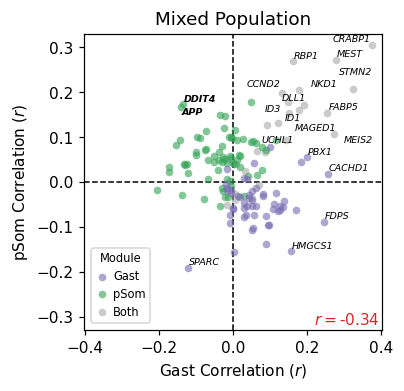

In [ ]:
from adjustText import adjust_text
fig, ax = plt.subplots(1, 1, figsize=(3.5, 3.5))
for mod, sdf in R.groupby('Module', observed=True):
    sdf.plot(kind='scatter', x='Gast', y='pSom', color=c_dict[mod], label=mod,
             s=25, alpha=.6, linewidth=0, ax=ax)
ax.axvline(0, color='k', lw=1, ls='--', zorder=0)
ax.axhline(0, color='k', lw=1, ls='--', zorder=0)
xlim = abs(np.asarray(ax.get_xlim())).max(); ylim = abs(np.asarray(ax.get_ylim())).max()
ax.set_xlim(-xlim, xlim); ax.set_ylim(-ylim, ylim)
n, texts = 20, []
for i in R.head(n).index:
    xi, yi = R.loc[i].Gast, R.loc[i].pSom
    fw = 'bold' if (xi < 0 and yi > 0) else 'normal'
    texts.append(ax.text(xi, yi, i, fontsize=6.25, fontstyle='italic', fontweight=fw))
adjust_text(texts=texts)
ax.legend(title='Module', loc='lower left', title_fontsize=7.5, handlelength=1,
          handletextpad=.5, borderaxespad=.65, fontsize=7.5, reverse=True)
ax.text(.99, .01, r'$r=$' + f'{rval}', transform=ax.transAxes, fontsize=10,
        color='tab:red', ha='right', va='bottom')
ax.set_title('Mixed Population')
ax.set_xlabel(r'Gast Correlation ($r$)'); ax.set_ylabel(r'pSom Correlation ($r$)')
fig.savefig(os.path.join(pth_fig, 'modules.pdf'), bbox_inches='tight'); plt.show()
print('saved modules.pdf | hub r =', rval)